# TP3 — XGBoost : prédire les hauts revenus (Correction)

Cours associé : [TP3_Cours.md](TP3_Cours.md) · Pense-bête : [Pense_bete_Pandas.md](../Pense_bete_Pandas.md)

## Contexte

Le jeu de données *Adult* est extrait du recensement américain de 1994. Pour 48 842 adultes, il décrit l'âge, le niveau d'études, la profession, la situation familiale, le temps de travail… et indique si leur revenu annuel dépasse **50 000 $**.

**Objectif** : prédire la classe `>50K`, en tirant le meilleur d'XGBoost, puis comprendre ce que le modèle a appris.

Comme au TP2, on y trouve des variables catégorielles nombreuses, des valeurs manquantes et des classes déséquilibrées (24 % de hauts revenus), mais avec sept fois plus de lignes.

## Déroulé

| Partie | Contenu |
|---|---|
| 1 | Chargement et préparation |
| 2 | Modèles de référence : régression logistique, arbre, forêt aléatoire |
| 3 | Premier modèle XGBoost |
| 4 | Arrêt anticipé |
| 5 | Interprétation, évaluation finale et synthèse |
| 6 | *Facultatif* : classes déséquilibrées |
| 7 | *Facultatif* : taux d'apprentissage et hyperparamètres |

Les cellules marquées `# TODO` sont à compléter. Les cellules ✍️ attendent une réponse rédigée.

⚙️ XGBoost fait partie du `requirements.txt` du cours. S'il manque dans votre environnement :

- avec **uv** : `uv pip install xgboost`
- avec **Conda** : `conda install -c conda-forge xgboost`

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, classification_report)

import xgboost as xgb
from xgboost import XGBClassifier

plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42
print("xgboost", xgb.__version__)

xgboost 3.4.1


## Partie 1 — Chargement et préparation

**1.1** Chargez `data/adult.csv.gz` dans `df` (pandas décompresse automatiquement). Affichez les dimensions, les types, les valeurs manquantes et la répartition de la colonne `class`.

In [2]:
# TODO : chargement et premier coup d'œil
df = pd.read_csv("data/adult.csv.gz")
print(df.shape)
print(df.isna().sum()[df.isna().sum() > 0])
print(df["class"].value_counts(normalize=True).round(3))
df.head()

(48842, 15)
workclass         2799
occupation        2809
native-country     857
dtype: int64
class
<=50K    0.761
>50K     0.239
Name: proportion, dtype: float64


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


**1.2** Préparez les données :

- créez la cible `y` valant 1 si `class == ">50K"`, 0 sinon ;
- supprimez de `X` les colonnes `class`, `fnlwgt` (un poids statistique du recensement, pas une caractéristique de la personne) et `education` (redondante avec `education-num`, qui code le même niveau d'études sous forme numérique) ;
- convertissez toutes les colonnes de type texte de `X` en type `category` (nécessaire pour qu'XGBoost les gère nativement).

Affichez la liste des colonnes catégorielles et numériques.

In [3]:
# TODO : cible, suppression de colonnes, conversion en category
y = (df["class"] == ">50K").astype(int)
X = df.drop(columns=["class", "fnlwgt", "education"])

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()
X[cat_cols] = X[cat_cols].astype("category")
print("catégorielles :", cat_cols)
print("numériques    :", num_cols)

catégorielles : ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
numériques    : ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']


**1.3** Découpez les données en trois jeux stratifiés : **entraînement 60 %**, **validation 20 %**, **test 20 %** (deux appels successifs à `train_test_split`). Le jeu de validation servira à l'arrêt anticipé et aux réglages ; le jeu de test uniquement à l'évaluation finale.

In [4]:
# TODO : découpage train / valid / test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=RANDOM_STATE)  # 0,25 × 80 % = 20 %
print(X_train.shape, X_valid.shape, X_test.shape)

(29304, 12) (9769, 12) (9769, 12)


## Partie 2 — Modèles de référence

Avant d'essayer XGBoost, il faut savoir d'où l'on part. Pour comparer les modèles, on utilisera l'**AUC** (insensible au seuil et adaptée au déséquilibre) et, en complément, l'exactitude et le F1.

Deux outils sont **fournis** ci-dessous :

- la fonction `evaluer`, qui calcule ces métriques sur le jeu de validation et les range dans un tableau ;
- le préprocesseur `preprocess`, identique à celui du TP2 : les modèles de scikit-learn ne gèrent ni les catégories ni les valeurs manquantes, il faut donc imputer, encoder et standardiser.

In [5]:
resultats = {}

def evaluer(nom, modele, X_eval=None, y_eval=None, duree=None):
    """Calcule les métriques sur le jeu de validation et les mémorise dans `resultats`."""
    X_eval = X_valid if X_eval is None else X_eval
    y_eval = y_valid if y_eval is None else y_eval
    proba = modele.predict_proba(X_eval)[:, 1]
    pred = (proba >= 0.5).astype(int)
    resultats[nom] = {
        "AUC": roc_auc_score(y_eval, proba),
        "exactitude": accuracy_score(y_eval, pred),
        "F1": f1_score(y_eval, pred),
        "durée (s)": duree,
    }
    return pd.DataFrame(resultats).T.round(3)

preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore")), cat_cols),
])

**2.1** Évaluez, sur le jeu de **validation**, un `DummyClassifier`, une régression logistique et un arbre de décision (`max_depth=8`). Chaque modèle est placé dans un `Pipeline` derrière une copie du préprocesseur (`clone(preprocess)`). Mesurez le temps d'entraînement avec `time.perf_counter()`.

In [6]:
# TODO : trois modèles de référence
references = {
    "dummy": DummyClassifier(strategy="most_frequent"),
    "logreg": LogisticRegression(max_iter=2000),
    "arbre (prof. 8)": DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
}
for nom, clf in references.items():
    pipe = Pipeline([("prep", clone(preprocess)), ("clf", clf)])
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    tableau = evaluer(nom, pipe, duree=time.perf_counter() - t0)
tableau

,AUC,exactitude,F1,durée (s)
dummy,0.500,0.761,0.000,0.039
logreg,0.907,0.852,0.658,0.091
arbre (prof. 8),0.908,0.860,0.677,0.088


**2.2** Ajoutez une forêt aléatoire (`RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1)`).

In [7]:
# TODO : forêt aléatoire
rf = Pipeline([("prep", clone(preprocess)),
               ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                              n_jobs=-1, random_state=RANDOM_STATE))])
t0 = time.perf_counter()
rf.fit(X_train, y_train)
evaluer("forêt aléatoire", rf, duree=time.perf_counter() - t0)

,AUC,exactitude,F1,durée (s)
dummy,0.500,0.761,0.000,0.039
logreg,0.907,0.852,0.658,0.091
arbre (prof. 8),0.908,0.860,0.677,0.088
forêt aléatoire,0.921,0.867,0.689,0.744


✅ **Éléments de réponse**

- Le `DummyClassifier` atteint 76 % d'exactitude (la proportion de revenus ≤ 50K) mais une AUC de 0,5 et un F1 nul : c'est pour cela qu'on ne juge pas sur l'exactitude seule.
- La régression logistique est déjà solide (AUC ≈ 0,91). Un arbre de profondeur 8 fait jeu égal avec elle.
- La forêt aléatoire fait mieux (AUC ≈ 0,92) : moyenner 300 arbres réduit la variance. Elle est en revanche nettement plus longue à entraîner.

## Partie 3 — Premier modèle XGBoost

**3.1** Entraînez un `XGBClassifier` avec ses réglages par défaut, en ajoutant seulement `enable_categorical=True`, `tree_method="hist"` et `random_state=RANDOM_STATE`. **Aucun préprocesseur n'est nécessaire** : XGBoost lit directement les colonnes `category` et les valeurs manquantes. Évaluez-le.

In [8]:
# TODO : XGBoost par défaut
xgb_defaut = XGBClassifier(enable_categorical=True, tree_method="hist", random_state=RANDOM_STATE)
t0 = time.perf_counter()
xgb_defaut.fit(X_train, y_train)
evaluer("xgboost (défaut)", xgb_defaut, duree=time.perf_counter() - t0)

,AUC,exactitude,F1,durée (s)
dummy,0.500,0.761,0.000,0.039
logreg,0.907,0.852,0.658,0.091
arbre (prof. 8),0.908,0.860,0.677,0.088
forêt aléatoire,0.921,0.867,0.689,0.744
xgboost (défaut),0.930,0.875,0.718,0.246


**3.2** Par défaut, XGBoost construit **100 arbres** de **profondeur 6** avec un **taux d'apprentissage de 0,3**. Comparez ce premier modèle aux modèles de référence : performance, temps d'entraînement, préparation des données nécessaire. Le taux d'apprentissage par défaut vous paraît-il prudent (voir la section 6.2 du cours) ?

✅ **Éléments de réponse**

XGBoost par défaut (100 arbres de profondeur 6, `learning_rate = 0.3`) dépasse déjà tous les modèles de référence en AUC, sans aucune préparation des données, et s'entraîne en une fraction du temps de la forêt aléatoire. Le taux d'apprentissage de 0,3 est élevé : on peut sans doute gagner encore en le baissant et en ajoutant des arbres, à condition de savoir quand s'arrêter.

## Partie 4 — Arrêt anticipé

**4.1** Entraînez un XGBoost avec `n_estimators=3000`, `learning_rate=0.05`, `max_depth=6`, `eval_metric="logloss"` en passant `eval_set=[(X_train, y_train), (X_valid, y_valid)]` à `fit` (avec `verbose=500`). **Sans** arrêt anticipé pour l'instant.

Récupérez les courbes de perte avec `evals_result()` et tracez la log loss d'entraînement et de validation en fonction du nombre d'arbres. Que constatez-vous ?

[0]	validation_0-logloss:0.52876	validation_1-logloss:0.52864


[500]	validation_0-logloss:0.22744	validation_1-logloss:0.27265


[1000]	validation_0-logloss:0.20916	validation_1-logloss:0.27906


[1500]	validation_0-logloss:0.19549	validation_1-logloss:0.28446


[2000]	validation_0-logloss:0.18798	validation_1-logloss:0.28938


[2500]	validation_0-logloss:0.17918	validation_1-logloss:0.29440


[2999]	validation_0-logloss:0.17281	validation_1-logloss:0.29895


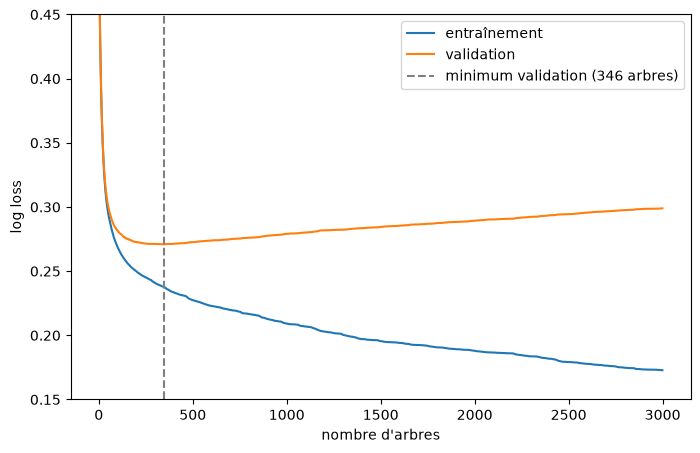

In [9]:
# TODO : courbes d'apprentissage sans arrêt anticipé
xgb_long = XGBClassifier(n_estimators=3000, learning_rate=0.05, max_depth=6,
                         eval_metric="logloss", enable_categorical=True,
                         tree_method="hist", random_state=RANDOM_STATE)
xgb_long.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_valid, y_valid)], verbose=500)

historique = xgb_long.evals_result()
perte_train = historique["validation_0"]["logloss"]
perte_valid = historique["validation_1"]["logloss"]
meilleur = int(np.argmin(perte_valid))

plt.plot(perte_train, label="entraînement")
plt.plot(perte_valid, label="validation")
plt.axvline(meilleur, color="gray", linestyle="--", label=f"minimum validation ({meilleur} arbres)")
plt.xlabel("nombre d'arbres")
plt.ylabel("log loss")
plt.ylim(0.15, 0.45)
plt.legend()
plt.show()

✅ **Éléments de réponse**

La perte d'entraînement diminue continuellement : le modèle apprend de mieux en mieux le jeu d'entraînement. La perte de validation diminue d'abord, atteint un **minimum** (vers 350 arbres), puis **remonte lentement** (0,299 à 3 000 arbres contre 0,272 au minimum) : au-delà, les arbres supplémentaires apprennent le bruit du jeu d'entraînement. C'est le sur-apprentissage, vu cette fois en fonction du nombre d'arbres.

**4.2** Reprenez le même modèle en ajoutant `early_stopping_rounds=50` dans le constructeur, et seulement le jeu de validation dans `eval_set`. Combien d'arbres sont retenus (`best_iteration`) ? Évaluez le modèle.

In [10]:
# TODO : arrêt anticipé
xgb_es = XGBClassifier(n_estimators=3000, learning_rate=0.05, max_depth=6,
                       eval_metric="logloss", early_stopping_rounds=50,
                       enable_categorical=True, tree_method="hist", random_state=RANDOM_STATE)
t0 = time.perf_counter()
xgb_es.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
print("arbres retenus :", xgb_es.best_iteration + 1)
evaluer("xgboost (lr 0.05 + arrêt)", xgb_es, duree=time.perf_counter() - t0)

arbres retenus : 347


,AUC,exactitude,F1,durée (s)
dummy,0.500,0.761,0.000,0.039
logreg,0.907,0.852,0.658,0.091
arbre (prof. 8),0.908,0.860,0.677,0.088
forêt aléatoire,0.921,0.867,0.689,0.744
xgboost (défaut),0.930,0.875,0.718,0.246
xgboost (lr 0.05 + arrêt),0.932,0.877,0.721,1.064


✅ **Éléments de réponse**

L'arrêt anticipé retient **347 arbres** : c'est le minimum de la courbe de validation repéré à la question 4.1. L'entraînement s'arrête 50 arbres plus loin, au lieu d'en construire 3 000. Avec un taux d'apprentissage de 0,05 et ce nombre d'arbres, l'AUC de validation passe de 0,930 (réglages par défaut) à 0,932 : un gain réel mais modeste.

Pour la suite du TP, on retient le modèle de la question 4.2 (taux d'apprentissage de 0,05 et arrêt anticipé).

In [11]:
xgb_final = xgb_es

## Partie 5 — Interprétation, évaluation finale et synthèse

**5.1** Tracez l'importance des variables de `xgb_final` selon deux définitions : `gain` et `weight` (`xgb_final.get_booster().get_score(importance_type=...)`). Les classements sont-ils les mêmes ?

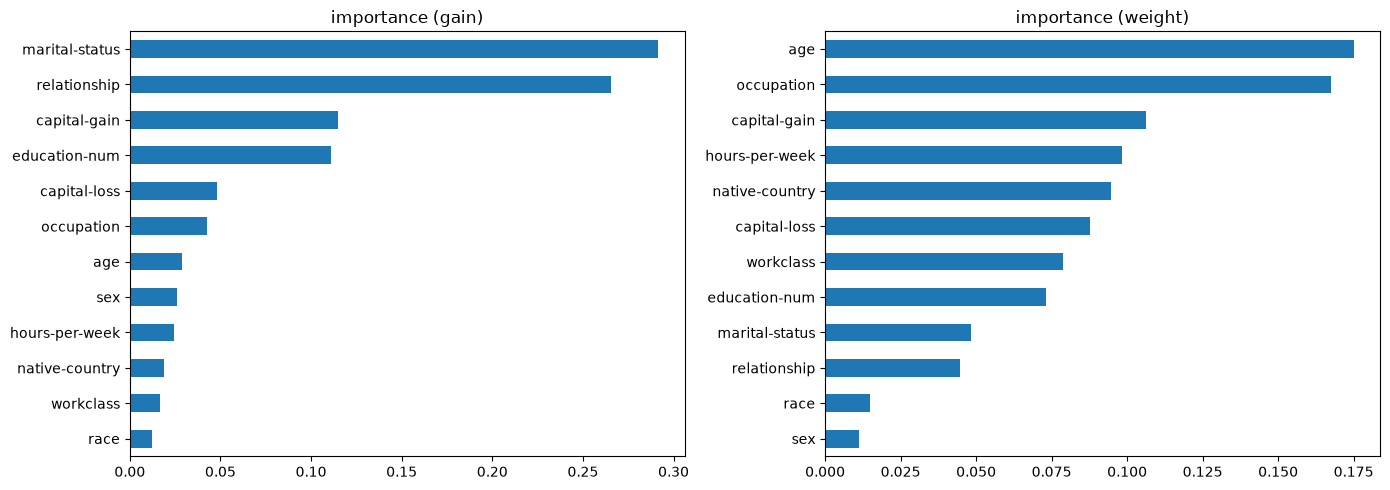

In [12]:
# TODO : importance des variables
booster = xgb_final.get_booster()
importances = pd.DataFrame({t: pd.Series(booster.get_score(importance_type=t)) for t in ["gain", "weight"]})
importances = importances / importances.sum()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, t in zip(axes, ["gain", "weight"]):
    importances[t].sort_values().plot.barh(ax=ax, title=f"importance ({t})")
plt.tight_layout()
plt.show()

**5.2** Les trois premières lignes, fournies, calculent les valeurs SHAP du jeu de validation (voir la section 8.2 du cours) : `shap_df` contient une ligne par individu et une colonne par variable. Tracez l'importance moyenne `|SHAP|` par variable. Enfin, affichez la décomposition de la prédiction pour **un** individu de votre choix : quelles variables poussent vers `>50K`, lesquelles vers `<=50K` ?

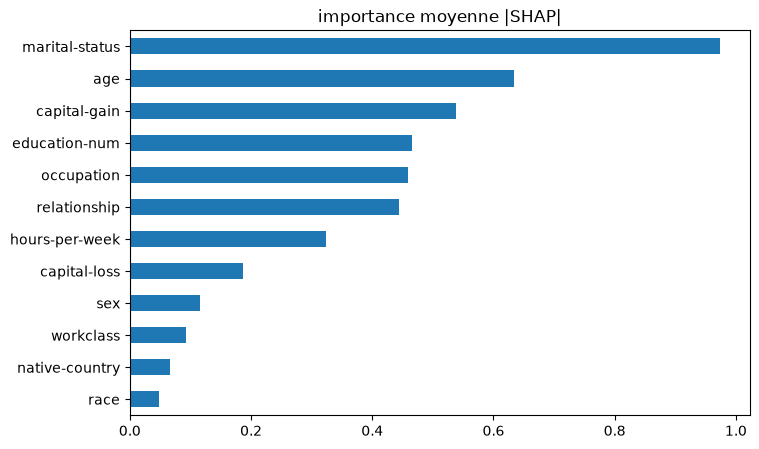

age                               33
workclass                    Private
education-num                      9
marital-status    Married-civ-spouse
occupation         Machine-op-inspct
relationship                 Husband
race                           White
sex                             Male
capital-gain                       0
capital-loss                       0
hours-per-week                    40
native-country         United-States
Name: 26921, dtype: object
probabilité >50K : 0.177


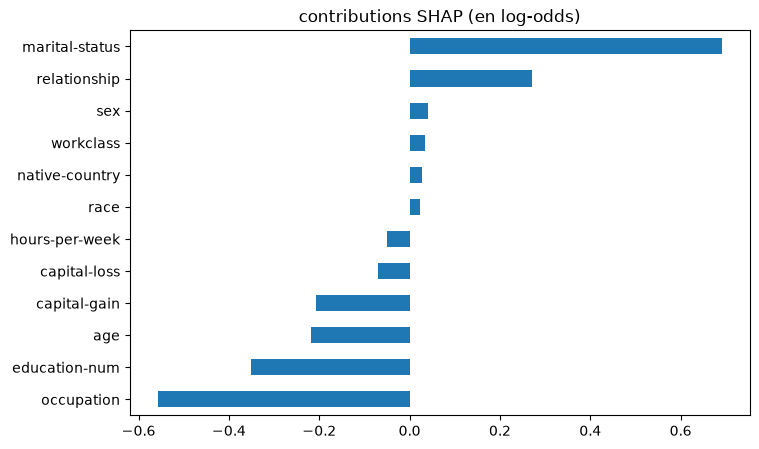

In [13]:
dvalid = xgb.DMatrix(X_valid, enable_categorical=True)
contribs = xgb_final.get_booster().predict(dvalid, pred_contribs=True, iteration_range=(0, xgb_final.best_iteration + 1))
shap_df = pd.DataFrame(contribs[:, :-1], columns=X_valid.columns, index=X_valid.index)

# TODO : importance moyenne |SHAP|, puis décomposition pour un individu

shap_df.abs().mean().sort_values().plot.barh(title="importance moyenne |SHAP|")
plt.show()

individu = X_valid.index[0]
print(X_valid.loc[individu])
print("probabilité >50K :", round(float(xgb_final.predict_proba(X_valid.loc[[individu]])[0, 1]), 3))
shap_df.loc[individu].sort_values().plot.barh(title="contributions SHAP (en log-odds)")
plt.show()

✅ **Éléments de réponse**

- Selon le `gain`, la situation familiale (`relationship`, `marital-status`) domine largement (plus de 50 % à elles deux), suivie du niveau d'études et des revenus du capital. Selon `weight`, ce sont `age`, `occupation`, `capital-gain` et `hours-per-week` qui arrivent en tête : des variables continues ou à nombreuses modalités, qui offrent beaucoup de coupures possibles et sont donc utilisées souvent, même quand chaque coupure apporte peu. **`weight` surestime ces variables** ; les deux classements ne se ressemblent pas.
- Avec SHAP, `marital-status` reste en tête, mais l'`age` remonte en deuxième position : il joue un rôle diffus mais constant dans presque toutes les prédictions, ce que le `gain` sous-estime. On retrouve ensuite `capital-gain`, `education-num` et `occupation`.
- Pour l'individu étudié (homme marié de 33 ans, opérateur sur machine, niveau d'études 9), la situation maritale et familiale pousse vers `>50K`, mais la profession et le niveau d'études tirent fortement vers `<=50K` : probabilité finale d'environ 0,18. SHAP donne ainsi le **sens** et l'**ampleur** de chaque effet, individu par individu.
- ⚠️ Ces liens sont des **associations** apprises dans des données de 1994, pas des causes. Le modèle reproduit aussi les biais du recensement (sexe, origine) : l'utiliser pour prendre des décisions sur des personnes poserait de sérieux problèmes d'équité.

**5.3** Évaluation finale. Affichez le tableau `resultats` complet. Puis évaluez **une seule fois** le modèle retenu (`xgb_final`, seuil 0,5) sur le jeu de **test**.

In [14]:
# TODO : tableau récapitulatif et évaluation finale sur le test
print(pd.DataFrame(resultats).T.round(3))
proba_test = xgb_final.predict_proba(X_test)[:, 1]
print("AUC test        :", round(roc_auc_score(y_test, proba_test), 4))
print("exactitude test :", round(accuracy_score(y_test, proba_test >= 0.5), 4))

                             AUC  exactitude     F1  durée (s)
dummy                      0.500       0.761  0.000      0.039
logreg                     0.907       0.852  0.658      0.091
arbre (prof. 8)            0.908       0.860  0.677      0.088
forêt aléatoire            0.921       0.867  0.689      0.744
xgboost (défaut)           0.930       0.875  0.718      0.246
xgboost (lr 0.05 + arrêt)  0.932       0.877  0.721      1.064
AUC test        : 0.9295
exactitude test : 0.8773


✅ **Éléments de réponse**

Les modèles XGBoost obtiennent la meilleure AUC de tous les modèles testés (0,93 contre 0,92 pour la forêt aléatoire et 0,91 pour la régression logistique). La performance sur le test (AUC 0,930, exactitude 87,7 %) est très proche de celle mesurée en validation : le modèle généralise bien et l'évaluation est honnête puisque le test n'a servi qu'à la fin.

**5.4** Synthèse. Un collègue vous demande : « J'ai un fichier clients et je veux prédire qui va résilier. Est-ce que je prends XGBoost, et à quoi dois-je faire attention ? » Répondez en quelques phrases, en vous appuyant sur ce que vous avez observé dans ce TP.

✅ **Éléments de réponse**

- **Oui, c'est un bon candidat** : des données tabulaires, des types mélangés, des valeurs manquantes. XGBoost a obtenu ici la meilleure AUC sans aucune préparation, en moins de temps que la forêt aléatoire.
- **Mais d'abord une référence** : la régression logistique était déjà à 0,91 d'AUC. Si le modèle doit être expliqué simplement, ou si l'écart est faible, le modèle simple peut suffire.
- **Précautions** : découper en entraînement / validation / test ; prendre un taux d'apprentissage modéré, beaucoup d'arbres et l'**arrêt anticipé** sur le jeu de validation ; ne pas juger sur l'exactitude puisque les classes sont déséquilibrées ; choisir le compromis précision / rappel selon le coût des erreurs ; lire l'importance et les valeurs SHAP comme des associations, pas comme des causes.

## Partie 6 — *Facultatif* : classes déséquilibrées

*À faire si vous avez terminé le reste.*

**6.1** Affichez le `classification_report` de `xgb_final` sur le jeu de validation. Quelle classe est la moins bien reconnue ?

In [15]:
# TODO : rapport de classification
print(classification_report(y_valid, xgb_final.predict(X_valid), target_names=["<=50K", ">50K"]))

              precision    recall  f1-score   support

       <=50K       0.90      0.94      0.92      7432
        >50K       0.79      0.66      0.72      2337

    accuracy                           0.88      9769
   macro avg       0.84      0.80      0.82      9769
weighted avg       0.87      0.88      0.87      9769



**6.2** Entraînez une variante `xgb_pondere` identique à `xgb_final` mais avec `scale_pos_weight` égal au rapport nombre de négatifs / nombre de positifs dans `y_train`. Comparez précision, rappel, F1 et AUC des deux modèles.

In [16]:
# TODO : pondération de la classe positive
poids = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight =", round(poids, 2))
xgb_pondere = clone(xgb_final).set_params(scale_pos_weight=poids)
xgb_pondere.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)

for nom, m in [("non pondéré", xgb_final), ("pondéré", xgb_pondere)]:
    pred = m.predict(X_valid)
    print(f"{nom:12s} précision={precision_score(y_valid, pred):.3f} rappel={recall_score(y_valid, pred):.3f} "
          f"F1={f1_score(y_valid, pred):.3f} AUC={roc_auc_score(y_valid, m.predict_proba(X_valid)[:, 1]):.4f}")

scale_pos_weight = 3.18


non pondéré  précision=0.789 rappel=0.664 F1=0.721 AUC=0.9321
pondéré      précision=0.621 rappel=0.860 F1=0.721 AUC=0.9307


✅ **Éléments de réponse**

- Les hauts revenus (`>50K`) sont la classe la moins bien reconnue : rappel de 0,66 pour une précision de 0,79 ; le modèle en « rate » un tiers.
- `scale_pos_weight` (≈ 3,2) fait monter le rappel à 0,86 mais la précision tombe à 0,62 ; le F1 ne bouge pas et l'**AUC est quasiment inchangée** : la pondération ne rend pas le modèle meilleur pour **classer** les individus, elle déplace le compromis précision / rappel.
- On obtiendrait le même type d'effet, sans réentraîner, en **baissant le seuil de décision** (voir le bonus). Le bon réglage dépend du coût métier des faux positifs et des faux négatifs.

## Partie 7 — *Facultatif* : taux d'apprentissage et hyperparamètres

*À faire si vous avez terminé le reste.* Jusqu'ici, on a fixé le taux d'apprentissage à 0,05 et laissé l'arrêt anticipé choisir le nombre d'arbres. Les autres réglages (sections 6.2 et 6.4 du cours) valent-ils la peine d'être ajustés ?

**7.1** Comparez trois taux d'apprentissage : 0,3, 0,1 et 0,02 (toujours avec arrêt anticipé). Pour chacun, affichez le nombre d'arbres retenus, l'AUC de validation et le temps d'entraînement. Concluez.

In [17]:
# TODO : comparaison de taux d'apprentissage
lignes = []
for lr in [0.3, 0.1, 0.02]:
    m = XGBClassifier(n_estimators=5000, learning_rate=lr, max_depth=6,
                      eval_metric="logloss", early_stopping_rounds=50,
                      enable_categorical=True, tree_method="hist", random_state=RANDOM_STATE)
    t0 = time.perf_counter()
    m.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
    lignes.append({"learning_rate": lr, "arbres": m.best_iteration + 1,
                   "AUC valid": roc_auc_score(y_valid, m.predict_proba(X_valid)[:, 1]),
                   "durée (s)": time.perf_counter() - t0})
pd.DataFrame(lignes).round(4)

,learning_rate,arbres,AUC valid,durée (s)
0,0.30,38,0.9314,0.2452
1,0.10,164,0.9317,0.5757
2,0.02,667,0.9320,1.8949


✅ **Éléments de réponse**

Plus le taux d'apprentissage est petit, plus il faut d'arbres (38 arbres à 0,3 ; 164 à 0,1 ; 667 à 0,02 : grossièrement inversement proportionnel à `learning_rate`) et plus l'entraînement est long. Le gain d'AUC d'un taux plus faible existe mais reste de l'ordre du millième. En pratique : `learning_rate` entre 0,05 et 0,1 pendant la mise au point, puis plus faible pour le modèle final si le temps de calcul le permet.

**7.2** Lancez une recherche aléatoire (`RandomizedSearchCV`, 20 combinaisons, validation croisée à 3 plis, `scoring="roc_auc"`) sur le jeu d'**entraînement** avec l'espace suivant, pour un XGBoost à `n_estimators=300` et `learning_rate=0.1` :

- `max_depth` : 3 à 9 ;
- `min_child_weight` : 1, 3, 5, 10 ;
- `subsample` : 0,6 à 1 ;
- `colsample_bytree` : 0,5 à 1.

*Cela prend de quelques secondes à une minute selon votre machine. `n_jobs=-1` dans `RandomizedSearchCV` parallélise les calculs.*

In [18]:
# TODO : recherche aléatoire
espace = {
    "max_depth": [3, 4, 5, 6, 7, 8, 9],
    "min_child_weight": [1, 3, 5, 10],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
}
base = XGBClassifier(n_estimators=300, learning_rate=0.1, enable_categorical=True,
                     tree_method="hist", random_state=RANDOM_STATE, n_jobs=1)
recherche = RandomizedSearchCV(base, espace, n_iter=20, cv=3, scoring="roc_auc",
                               random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.perf_counter()
recherche.fit(X_train, y_train)
print(f"{time.perf_counter() - t0:.0f} s")
print(recherche.best_params_, round(recherche.best_score_, 4))

5 s
{'subsample': 1.0, 'min_child_weight': 1, 'max_depth': 5, 'colsample_bytree': 0.8} 0.9263


**7.3** Affichez les 5 meilleures combinaisons (`cv_results_`). L'écart entre elles est-il important ?

In [19]:
# TODO : meilleures combinaisons
res = pd.DataFrame(recherche.cv_results_)
colonnes = ["param_max_depth", "param_min_child_weight", "param_subsample",
            "param_colsample_bytree", "mean_test_score", "std_test_score"]
res.sort_values("mean_test_score", ascending=False)[colonnes].head().round(4)

,param_max_depth,param_min_child_weight,param_subsample,param_colsample_bytree,mean_test_score,std_test_score
8,5,1,1.0,0.8,0.9263,0.0017
16,4,10,1.0,0.5,0.9260,0.0021
3,4,10,1.0,0.9,0.9256,0.0018
17,5,5,0.8,0.6,0.9246,0.0018
11,8,5,1.0,0.6,0.9244,0.0017


**7.4** Entraînez un modèle `xgb_regle` avec les meilleurs hyperparamètres trouvés, un `learning_rate` de 0,03, `n_estimators=5000` et l'arrêt anticipé sur le jeu de validation. Évaluez-le et comparez-le au modèle retenu en partie 4.

In [20]:
# TODO : modèle réglé
xgb_regle = XGBClassifier(**recherche.best_params_, n_estimators=5000, learning_rate=0.03,
                          eval_metric="logloss", early_stopping_rounds=100,
                          enable_categorical=True, tree_method="hist", random_state=RANDOM_STATE)
t0 = time.perf_counter()
xgb_regle.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
print("arbres retenus :", xgb_regle.best_iteration + 1)
evaluer("xgboost (réglé)", xgb_regle, duree=time.perf_counter() - t0)

arbres retenus : 809


,AUC,exactitude,F1,durée (s)
dummy,0.500,0.761,0.000,0.039
logreg,0.907,0.852,0.658,0.091
arbre (prof. 8),0.908,0.860,0.677,0.088
forêt aléatoire,0.921,0.867,0.689,0.744
xgboost (défaut),0.930,0.875,0.718,0.246
xgboost (lr 0.05 + arrêt),0.932,0.877,0.721,1.064
xgboost (réglé),0.932,0.877,0.721,2.069


✅ **Éléments de réponse**

- Les meilleures combinaisons sont très proches : les écarts d'AUC sont de l'ordre du millième, c'est-à-dire du même ordre que l'écart-type entre plis. XGBoost est **robuste** dans une large zone de réglages raisonnables.
- Le modèle réglé obtient sur le jeu de validation **exactement les mêmes scores** que le modèle de la partie 4 (AUC 0,932, exactitude 0,877, F1 0,721), pour un temps d'entraînement deux fois plus long : ici, le réglage fin n'apporte **aucun gain mesurable**.
- L'essentiel du gain venait du passage au boosting et de l'arrêt anticipé. C'est typique : mieux vaut consacrer son temps aux **données** et à la rigueur de l'**évaluation** qu'à une recherche exhaustive d'hyperparamètres.

## Pour aller plus loin (bonus)

- Sans pondération, cherchez le **seuil de décision** qui maximise le F1 sur le jeu de validation (seuils de 0,1 à 0,9 par pas de 0,01) et tracez précision, rappel et F1 en fonction du seuil.
- Mesurez l'**équité** du modèle : comparez le rappel et le taux de prédictions positives entre hommes et femmes.
- Remplacez XGBoost par `HistGradientBoostingClassifier` de scikit-learn (paramètre `categorical_features="from_dtype"`) : performances et temps sont-ils comparables ?
- Installez la bibliothèque `shap` et tracez un `shap.summary_plot` (nuage de points des valeurs SHAP colorées par la valeur de la variable).

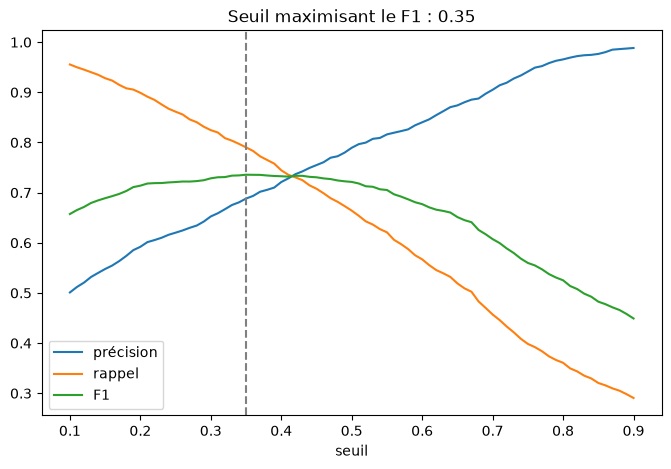

,précision,rappel,F1
0.50,0.789,0.664,0.721
0.35,0.688,0.790,0.736


In [21]:
# Bonus : choix du seuil
proba_valid = xgb_final.predict_proba(X_valid)[:, 1]
seuils = np.round(np.arange(0.10, 0.91, 0.01), 2)
courbes = pd.DataFrame({
    "précision": [precision_score(y_valid, proba_valid >= s) for s in seuils],
    "rappel": [recall_score(y_valid, proba_valid >= s) for s in seuils],
    "F1": [f1_score(y_valid, proba_valid >= s) for s in seuils],
}, index=seuils)
seuil_opt = courbes["F1"].idxmax()
courbes.plot()
plt.axvline(seuil_opt, color="gray", linestyle="--")
plt.xlabel("seuil")
plt.title(f"Seuil maximisant le F1 : {seuil_opt:.2f}")
plt.show()
courbes.loc[[0.5, seuil_opt]].round(3)

In [22]:
# Bonus : équité selon le sexe
pred_valid = xgb_final.predict(X_valid)
equite = pd.DataFrame({"sexe": X_valid["sex"], "y": y_valid, "pred": pred_valid})
equite.groupby("sexe", observed=True).apply(
    lambda g: pd.Series({"taux réel >50K": g["y"].mean(),
                         "taux prédit >50K": g["pred"].mean(),
                         "rappel": recall_score(g["y"], g["pred"])}),
    include_groups=False).round(3)

,taux réel >50K,taux prédit >50K,rappel
sexe,,,
Female,0.113,0.085,0.598
Male,0.302,0.259,0.676
